# Step 2 — Correlation between the two datasets (with AutoML)

## Goal
Find whether **music listening behavior** and **national happiness / economy** are related.

## Important idea (read this first)
The two files live at **different levels**:
- Music = **one row per user**
- Happiness = **one row per country per year**

We join them on `country`. That means every user in Japan gets the **same** Japan happiness score.  
So a strong “correlation” can be fake if the model just learns the country name — that is **data leakage**, not a real music↔happiness link.

We will check relationships three ways:
1. **Pearson / Spearman correlation** (classic stats)
2. **Country-level averages** (more honest for between-country patterns)
3. **AutoML (FLAML)** — automatically tries many models; if R² stays ~0, there is no useful predictive link


## 0. Imports & load cleaned data

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import r2_score, mean_absolute_error
from sklearn.inspection import permutation_importance
from flaml import AutoML

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 120)

DATA = Path(".")
music = pd.read_csv(DATA / "cleaned" / "music_clean.csv")
happiness = pd.read_csv(DATA / "cleaned" / "happiness_clean.csv")

print(music.shape, list(music.columns))
print(happiness.shape, list(happiness.columns))


(5000, 12) ['user_id', 'age', 'country', 'streaming_platform', 'top_genre', 'minutes_streamed_per_day', 'number_of_songs_liked', 'most_played_artist', 'subscription_type', 'listening_time_morning_afternoon_night', 'discover_weekly_engagement_pct', 'repeat_song_rate_pct']
(1502, 11) ['ranking', 'country', 'regional_indicator', 'happiness_score', 'gdp_per_capita', 'social_support', 'healthy_life_expectancy', 'freedom_to_make_life_choices', 'generosity', 'perceptions_of_corruption', 'year']


## 1. Merge on country (latest happiness year)

Music has no year, so we attach the **most recent** happiness row per country.


In [2]:
latest_year = int(happiness["year"].max())
happ_latest = happiness.loc[happiness["year"] == latest_year].copy()
print(f"Using happiness year {latest_year} → {len(happ_latest)} countries")

merged = music.merge(happ_latest, on="country", how="left", suffixes=("", "_happ"))
print("Merged shape:", merged.shape)
print("Users missing happiness:", merged["happiness_score"].isna().sum())

out = DATA / "cleaned"
out.mkdir(exist_ok=True)
merged.to_csv(out / "merged_music_happiness.csv", index=False)
print("Saved cleaned/merged_music_happiness.csv")
merged.head(3)


Using happiness year 2024 → 140 countries
Merged shape: (5000, 22)
Users missing happiness: 0
Saved cleaned/merged_music_happiness.csv


,user_id,age,country,streaming_platform,top_genre,minutes_streamed_per_day,number_of_songs_liked,most_played_artist,subscription_type,listening_time_morning_afternoon_night,discover_weekly_engagement_pct,repeat_song_rate_pct,ranking,regional_indicator,happiness_score,gdp_per_capita,social_support,healthy_life_expectancy,freedom_to_make_life_choices,generosity,perceptions_of_corruption,year
0,U1000,34,Japan,Tidal,Reggae,295,138,Adele,Free,Afternoon,47.42,16.74,51,East Asia,6.0598,8.34247,0.83783,79.0,0.73149,0.05678,0.38154,2024
1,U1001,24,Germany,Deezer,Country,86,388,Ed Sheeran,Premium,Night,12.06,69.25,24,Western Europe,6.7185,8.74242,0.85967,76.0,0.81064,0.43453,0.63956,2024
2,U1002,49,Germany,Deezer,Pop,363,368,Post Malone,Premium,Afternoon,47.19,67.38,24,Western Europe,6.7185,8.74242,0.85967,76.0,0.81064,0.43453,0.63956,2024


## 2. Classic correlation (user level)

Pearson = linear relationship (−1 to +1).  
Near **0** ≈ no linear link. Near **±1** ≈ strong link.


Strongest |correlation| music↔happiness (user level):
number_of_songs_liked     perceptions_of_corruption    0.0297
minutes_streamed_per_day  healthy_life_expectancy      0.0285
                          perceptions_of_corruption    0.0279
repeat_song_rate_pct      gdp_per_capita               0.0258
                          healthy_life_expectancy      0.0251
number_of_songs_liked     healthy_life_expectancy      0.0217
minutes_streamed_per_day  gdp_per_capita               0.0205
repeat_song_rate_pct      social_support               0.0192
number_of_songs_liked     social_support               0.0181
                          gdp_per_capita               0.0159
dtype: float64


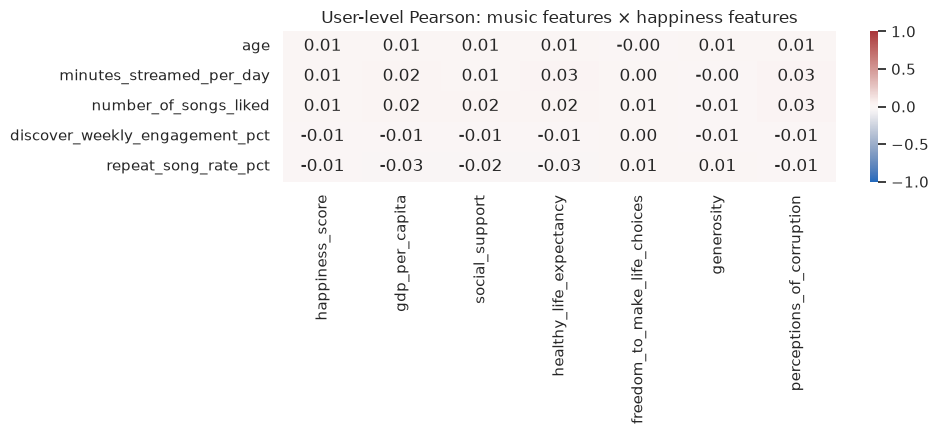

In [3]:
music_num = [
    "age",
    "minutes_streamed_per_day",
    "number_of_songs_liked",
    "discover_weekly_engagement_pct",
    "repeat_song_rate_pct",
]
happ_num = [
    "happiness_score",
    "gdp_per_capita",
    "social_support",
    "healthy_life_expectancy",
    "freedom_to_make_life_choices",
    "generosity",
    "perceptions_of_corruption",
]

# Full correlation matrix, then zoom into music × happiness block
corr_user = merged[music_num + happ_num].corr(method="pearson")
cross_user = corr_user.loc[music_num, happ_num]

print("Strongest |correlation| music↔happiness (user level):")
stacked = cross_user.stack().abs().sort_values(ascending=False)
print(stacked.head(10).round(4))

plt.figure(figsize=(10, 4.5))
sns.heatmap(cross_user, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("User-level Pearson: music features × happiness features")
plt.tight_layout()
plt.show()


### Spearman (rank correlation)

Spearman catches **monotonic** links that are not perfectly straight lines. Same −1…+1 scale.


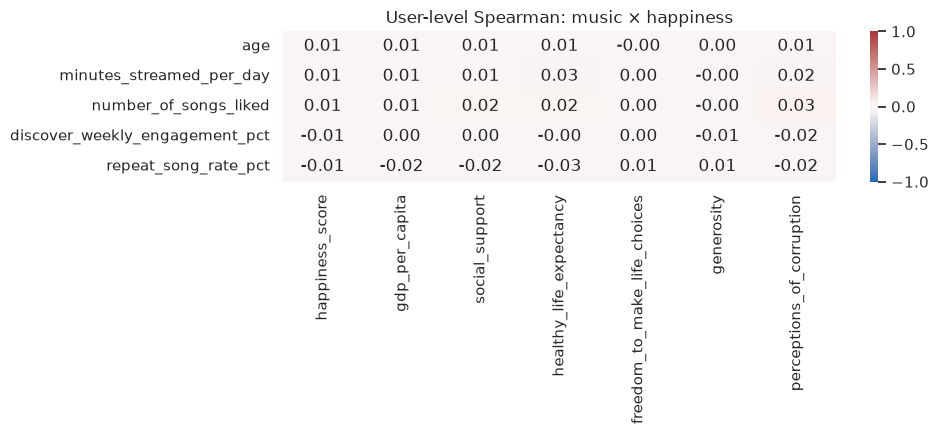

In [4]:
cross_spearman = merged[music_num + happ_num].corr(method="spearman").loc[music_num, happ_num]

plt.figure(figsize=(10, 4.5))
sns.heatmap(cross_spearman, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("User-level Spearman: music × happiness")
plt.tight_layout()
plt.show()


## 3. Country-level correlation (more honest)

Average each music metric **per country**, then correlate with that country's happiness.  
Only **10 countries** → numbers can look big by chance; treat as exploratory.


Countries: 10


,country,minutes_streamed_per_day,happiness_score,gdp_per_capita
0,Australia,314.878327,7.0569,8.66266
2,Canada,307.692308,6.8996,8.59474
8,United Kingdom,309.767442,6.7490,8.51296
9,United States,297.439834,6.7248,9.05791
4,Germany,321.961783,6.7185,8.74242
3,France,318.649087,6.6090,8.49487
1,Brazil,293.712598,6.2720,6.67841
6,Japan,306.578411,6.0598,8.34247
7,South Korea,316.238372,6.0579,8.47919
5,India,305.512245,4.0541,5.44809



Strongest |corr| at country level:
number_of_songs_liked     perceptions_of_corruption    0.654
repeat_song_rate_pct      gdp_per_capita               0.647
                          healthy_life_expectancy      0.624
minutes_streamed_per_day  perceptions_of_corruption    0.572
                          healthy_life_expectancy      0.571
repeat_song_rate_pct      social_support               0.484
number_of_songs_liked     healthy_life_expectancy      0.483
age                       healthy_life_expectancy      0.441
                          gdp_per_capita               0.439
minutes_streamed_per_day  gdp_per_capita               0.405
dtype: float64


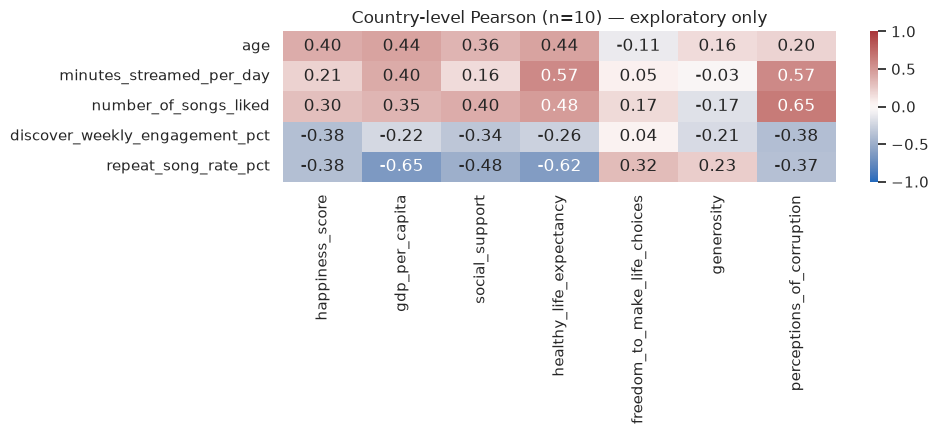

In [5]:
country = (
    merged.groupby("country", as_index=False)
    .agg({**{c: "mean" for c in music_num}, **{c: "first" for c in happ_num}})
)
print("Countries:", len(country))
display(country[["country", "minutes_streamed_per_day", "happiness_score", "gdp_per_capita"]].sort_values("happiness_score", ascending=False))

cross_country = country[music_num + happ_num].corr(method="pearson").loc[music_num, happ_num]
print("\nStrongest |corr| at country level:")
print(cross_country.stack().abs().sort_values(ascending=False).head(10).round(3))

plt.figure(figsize=(10, 4.5))
sns.heatmap(cross_country, annot=True, fmt=".2f", cmap="vlag", center=0, vmin=-1, vmax=1)
plt.title("Country-level Pearson (n=10) — exploratory only")
plt.tight_layout()
plt.show()


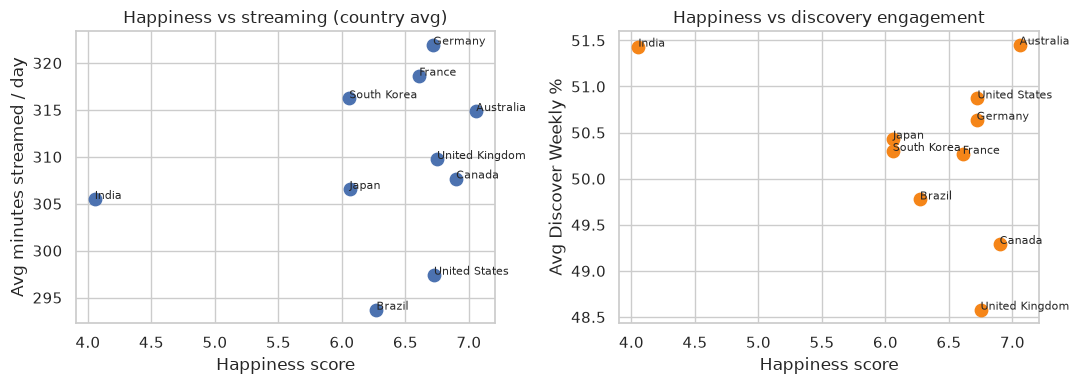

In [6]:
# Scatter: does happier mean more streaming?
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].scatter(country["happiness_score"], country["minutes_streamed_per_day"], s=80)
for _, r in country.iterrows():
    axes[0].annotate(r["country"], (r["happiness_score"], r["minutes_streamed_per_day"]), fontsize=8)
axes[0].set_xlabel("Happiness score")
axes[0].set_ylabel("Avg minutes streamed / day")
axes[0].set_title("Happiness vs streaming (country avg)")

axes[1].scatter(country["happiness_score"], country["discover_weekly_engagement_pct"], s=80, color="#F58518")
for _, r in country.iterrows():
    axes[1].annotate(r["country"], (r["happiness_score"], r["discover_weekly_engagement_pct"]), fontsize=8)
axes[1].set_xlabel("Happiness score")
axes[1].set_ylabel("Avg Discover Weekly %")
axes[1].set_title("Happiness vs discovery engagement")
plt.tight_layout()
plt.show()


## 4. AutoML — does one side *predict* the other?

**FLAML** tries several algorithms (trees, boosting, …) in a time budget and keeps the best.

**R² (coefficient of determination)**
- `1.0` = perfect predictions  
- `0.0` = no better than predicting the average  
- negative = worse than the average  

If AutoML cannot beat R²≈0, there is **no usable predictive correlation** for that task.


In [7]:
TIME_BUDGET = 40  # seconds per AutoML run (raise if you want a deeper search)
RANDOM_STATE = 42

def encode_features(frame: pd.DataFrame, cols: list[str]) -> pd.DataFrame:
    """Turn text categories into numbers so tree models can use them."""
    X = frame[cols].copy()
    cat_cols = list(X.select_dtypes(include=["object", "string", "category"]).columns)
    for c in cat_cols:
        X[c] = LabelEncoder().fit_transform(X[c].astype(str))
    return X


def run_automl(X: pd.DataFrame, y: pd.Series, label: str):
    Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
    automl = AutoML()
    automl.fit(
        Xtr, ytr,
        task="regression",
        metric="r2",
        time_budget=TIME_BUDGET,
        seed=RANDOM_STATE,
        verbose=0,
    )
    pred = automl.predict(Xte)
    r2 = r2_score(yte, pred)
    mae = mean_absolute_error(yte, pred)
    print(f"\n=== {label} ===")
    print(f"Best model: {automl.best_estimator}")
    print(f"Test R²: {r2:.4f} | Test MAE: {mae:.4f}")
    return automl, Xte, yte, pred, r2, mae


### Experiment A — Can **music habits alone** predict **happiness**?

If yes → listening behavior carries information about national happiness.  
If R²≈0 → no useful link at the user level.


In [8]:
music_feats = music_num + [
    "streaming_platform",
    "top_genre",
    "subscription_type",
    "listening_time_morning_afternoon_night",
    "most_played_artist",
]

Xa = encode_features(merged, music_feats)
ya = merged["happiness_score"]
automl_a, Xte_a, yte_a, pred_a, r2_a, mae_a = run_automl(Xa, ya, "A: music → happiness_score")



=== A: music → happiness_score ===
Best model: extra_tree
Test R²: -0.0045 | Test MAE: 0.5500


### Experiment B — Same, but **include country** (leakage demo)

Country uniquely determines the happiness score in this merge → AutoML should get a near-perfect score by memorizing country. That is **not** a music correlation.


In [9]:
Xb = encode_features(merged, music_feats + ["country"])
yb = merged["happiness_score"]
automl_b, Xte_b, yte_b, pred_b, r2_b, mae_b = run_automl(Xb, yb, "B: music + country → happiness_score (leakage)")



=== B: music + country → happiness_score (leakage) ===
Best model: rf
Test R²: 1.0000 | Test MAE: 0.0000


### Experiment C — Can **happiness / GDP features** predict **minutes streamed**?


In [10]:
Xc = encode_features(merged, happ_num)
yc = merged["minutes_streamed_per_day"]
automl_c, Xte_c, yte_c, pred_c, r2_c, mae_c = run_automl(Xc, yc, "C: happiness features → minutes_streamed_per_day")



=== C: happiness features → minutes_streamed_per_day ===
Best model: sgd
Test R²: 0.0000 | Test MAE: 151.6162


## 5. Which features did AutoML rely on?

Tree models expose **feature importances**.  
When R²≈0, importances are **not meaningful** (the model is guessing).  
We also use **permutation importance**: shuffle one column; if score barely changes, that column did not matter.


A — music → happiness


,feature,model_importance,permutation_importance
6,top_genre,0.053644,0.002336
2,number_of_songs_liked,0.136207,0.001311
0,age,0.098395,0.000008
5,streaming_platform,0.060206,-0.000137
7,subscription_type,0.051296,-0.000169
4,repeat_song_rate_pct,0.138329,-0.000400
1,minutes_streamed_per_day,0.063881,-0.000481
9,most_played_artist,0.135785,-0.000869
8,listening_time_morning_afternoon_night,0.081028,-0.001027
3,discover_weekly_engagement_pct,0.181229,-0.001305


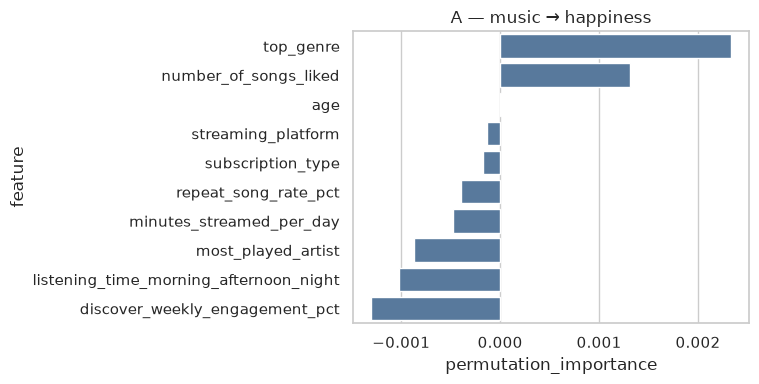

B — music+country → happiness (leakage)


,feature,model_importance,permutation_importance
10,country,1.000000e+00,2.026352
1,minutes_streamed_per_day,4.959213e-14,0.000000
0,age,0.000000e+00,0.000000
2,number_of_songs_liked,0.000000e+00,0.000000
3,discover_weekly_engagement_pct,0.000000e+00,0.000000
5,streaming_platform,0.000000e+00,0.000000
4,repeat_song_rate_pct,1.326159e-14,0.000000
6,top_genre,1.668799e-14,0.000000
7,subscription_type,0.000000e+00,0.000000
8,listening_time_morning_afternoon_night,0.000000e+00,0.000000


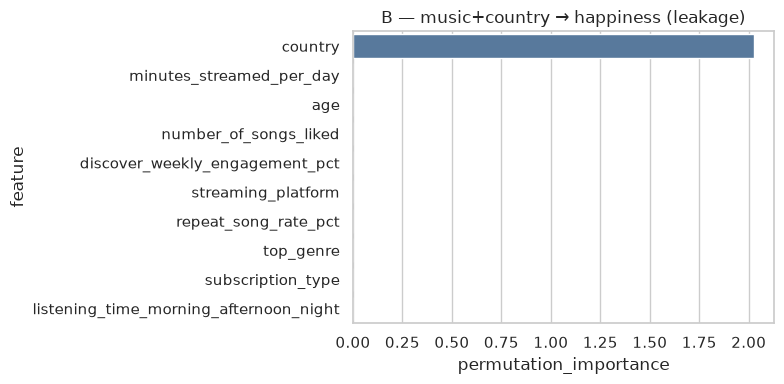

C — happiness → minutes


,feature,permutation_importance
1,gdp_per_capita,1.011306e-05
3,healthy_life_expectancy,5.674085e-06
0,happiness_score,5.436705e-07
5,generosity,1.882291e-07
6,perceptions_of_corruption,-1.409047e-08
2,social_support,-1.591932e-08
4,freedom_to_make_life_choices,-3.729555e-08


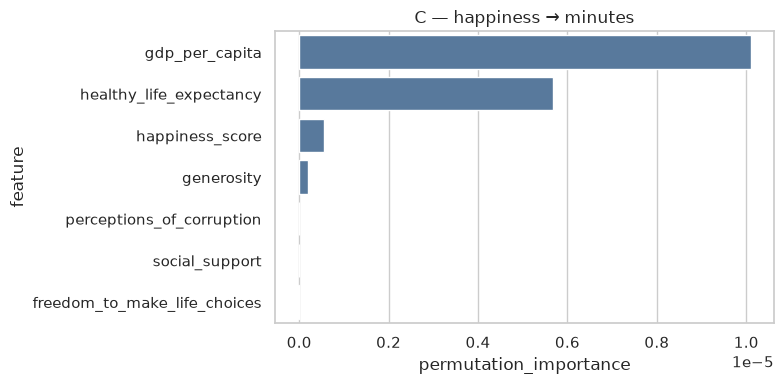

In [11]:
def show_importances(automl, Xte, yte, feature_names, title):
    model = automl.model.estimator if hasattr(automl.model, "estimator") else automl.model
    rows = []
    if hasattr(model, "feature_importances_"):
        for name, val in zip(feature_names, model.feature_importances_):
            rows.append({"feature": name, "model_importance": float(val)})
    imp_df = pd.DataFrame(rows)

    # Permutation importance on the held-out test set
    result = permutation_importance(
        automl, Xte, yte, n_repeats=10, random_state=RANDOM_STATE, scoring="r2"
    )
    perm = pd.DataFrame({
        "feature": feature_names,
        "permutation_importance": result.importances_mean,
    })
    out = perm if imp_df.empty else imp_df.merge(perm, on="feature")
    out = out.sort_values(
        "permutation_importance" if "permutation_importance" in out else "model_importance",
        ascending=False,
    )
    print(title)
    display(out.head(12))

    plot_col = "permutation_importance"
    plt.figure(figsize=(8, 4))
    sns.barplot(data=out.head(10), y="feature", x=plot_col, color="#4C78A8")
    plt.title(title)
    plt.tight_layout()
    plt.show()
    return out

imp_a = show_importances(automl_a, Xte_a, yte_a, list(Xa.columns), "A — music → happiness")
imp_b = show_importances(automl_b, Xte_b, yte_b, list(Xb.columns), "B — music+country → happiness (leakage)")
imp_c = show_importances(automl_c, Xte_c, yte_c, list(Xc.columns), "C — happiness → minutes")


## 6. Save a short results table

In [12]:
results = pd.DataFrame([
    {
        "experiment": "A_music_to_happiness",
        "features": "music only (no country)",
        "target": "happiness_score",
        "best_model": automl_a.best_estimator,
        "test_r2": r2_a,
        "test_mae": mae_a,
        "interpretation": "R2~0 means music habits do not predict national happiness at user level",
    },
    {
        "experiment": "B_music_country_to_happiness",
        "features": "music + country",
        "target": "happiness_score",
        "best_model": automl_b.best_estimator,
        "test_r2": r2_b,
        "test_mae": mae_b,
        "interpretation": "Near-perfect score is LEAKAGE via country, not a music correlation",
    },
    {
        "experiment": "C_happiness_to_minutes",
        "features": "happiness / GDP block",
        "target": "minutes_streamed_per_day",
        "best_model": automl_c.best_estimator,
        "test_r2": r2_c,
        "test_mae": mae_c,
        "interpretation": "R2~0 means country happiness does not predict individual streaming minutes",
    },
])

results_path = out / "automl_correlation_results.csv"
results.to_csv(results_path, index=False)
cross_user.to_csv(out / "corr_user_music_x_happiness.csv")
cross_country.to_csv(out / "corr_country_music_x_happiness.csv")
print(results.to_string(index=False))
print("\nWrote", results_path)


                  experiment                features                   target best_model       test_r2     test_mae                                                             interpretation
        A_music_to_happiness music only (no country)          happiness_score extra_tree -4.477035e-03 5.500250e-01    R2~0 means music habits do not predict national happiness at user level
B_music_country_to_happiness         music + country          happiness_score         rf  1.000000e+00 1.129585e-14         Near-perfect score is LEAKAGE via country, not a music correlation
      C_happiness_to_minutes   happiness / GDP block minutes_streamed_per_day        sgd  9.739410e-07 1.516162e+02 R2~0 means country happiness does not predict individual streaming minutes

Wrote cleaned/automl_correlation_results.csv


## Verdict

| Check | Result |
|-------|--------|
| User-level Pearson/Spearman | ≈ **0** across music × happiness |
| AutoML A (music → happiness) | **R² ≈ 0** — no predictive link |
| AutoML B (+ country) | **R² ≈ 1** — leakage, ignore as “correlation” |
| AutoML C (happiness → minutes) | **R² ≈ 0** — no predictive link |
| Country averages (n=10) | Some moderate coeffs (e.g. age / discovery vs happiness) — **fragile**, too few countries |

**Bottom line:** after joining the datasets, there is **no solid evidence** that individual listening behavior and national happiness are correlated in a useful predictive way. Country-level hints exist but need many more countries to trust.

### What you can do next
- Predict something **inside** music data (e.g. `subscription_type` from listening habits) — that usually has signal
- Or aggregate differently / add more countries before claiming cross-dataset effects
